Notebook này phân tích ảnh hưởng của positive threshold (2.5, 3.0, 3.5, 4.0, 4.5) đến:
- Phân bố rating trong train/test
- Số positive interactions per user (đặc biệt là singleton users)
- Khả năng dùng stratified split (train_test_split với stratify=userId)
- So sánh 2 phương pháp chia train/val: Stratified vs Per-user Group Split
- Verify temporal split khả thi trên data (Section 8)

Mục tiêu: Cung cấp dữ liệu để quyết định threshold phù hợp cho notebook 02-cf-experiments.

## Nội dung
1. Setup & Load Data
2. Rating Distribution Analysis
3. Threshold Comparison Table
4. Per-User Positive Count Distribution
5. Stratified Split Feasibility Check
6. Train/Val Split Simulation
7. Recommendation & Next Steps
8. Temporal Split Feasibility Check


## 1. Setup & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys

# Add project root to path (same pattern as notebook 02)
_current = Path.cwd().resolve()
PROJECT_ROOT = _current
while PROJECT_ROOT.name != "RecommendationSystem" and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import DataPreprocessor

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Setup done. PROJECT_ROOT:", PROJECT_ROOT)

Setup done. PROJECT_ROOT: /home/huyquang/Workspace/Personal/PyCharmProjects/RecommendationSystem


In [2]:
# Load processed train/test splits (same as notebook 02)
train_df = pd.read_csv(PROJECT_ROOT / 'data/processed/train_ml25m.csv')
test_df = pd.read_csv(PROJECT_ROOT / 'data/processed/test_ml25m.csv')

print(f"Train: {len(train_df):,} ratings")
print(f"Test: {len(test_df):,} ratings")
print(f"Train users: {train_df['userId'].nunique():,}")
print(f"Test users: {test_df['userId'].nunique():,}")
print(f"Train movies: {train_df['movieId'].nunique():,}")
print(f"Test movies: {test_df['movieId'].nunique():,}")

Train: 17,500,066 ratings
Test: 548,359 ratings
Train users: 122,029
Test users: 4,587
Train movies: 22,931
Test movies: 18,624


## 2. Rating Distribution Analysis

Hiểu phân bố rating để quyết định threshold hợp lý.

In [3]:
# Basic rating statistics
print("=== TRAIN Rating Stats ===")
print(f"Mean:   {train_df['rating'].mean():.3f}")
print(f"Median: {train_df['rating'].median():.3f}")
print(f"Std:    {train_df['rating'].std():.3f}")
print(f"Min:    {train_df['rating'].min():.3f}")
print(f"Max:    {train_df['rating'].max():.3f}")
print()
print("=== TEST Rating Stats ===")
print(f"Mean:   {test_df['rating'].mean():.3f}")
print(f"Median: {test_df['rating'].median():.3f}")
print(f"Std:    {test_df['rating'].std():.3f}")
print()
print("=== Rating value counts (TRAIN) ===")
print(train_df['rating'].value_counts().sort_index(ascending=False))

=== TRAIN Rating Stats ===
Mean:   3.525
Median: 4.000
Std:    1.052
Min:    0.500
Max:    5.000

=== TEST Rating Stats ===
Mean:   3.354
Median: 3.500
Std:    1.005

=== Rating value counts (TRAIN) ===
rating
5.0    2543081
4.5    1330085
4.0    4877820
3.5    1908298
3.0    3769090
2.5     766786
2.0    1258106
1.5     241776
1.0     599129
0.5     205895
Name: count, dtype: int64


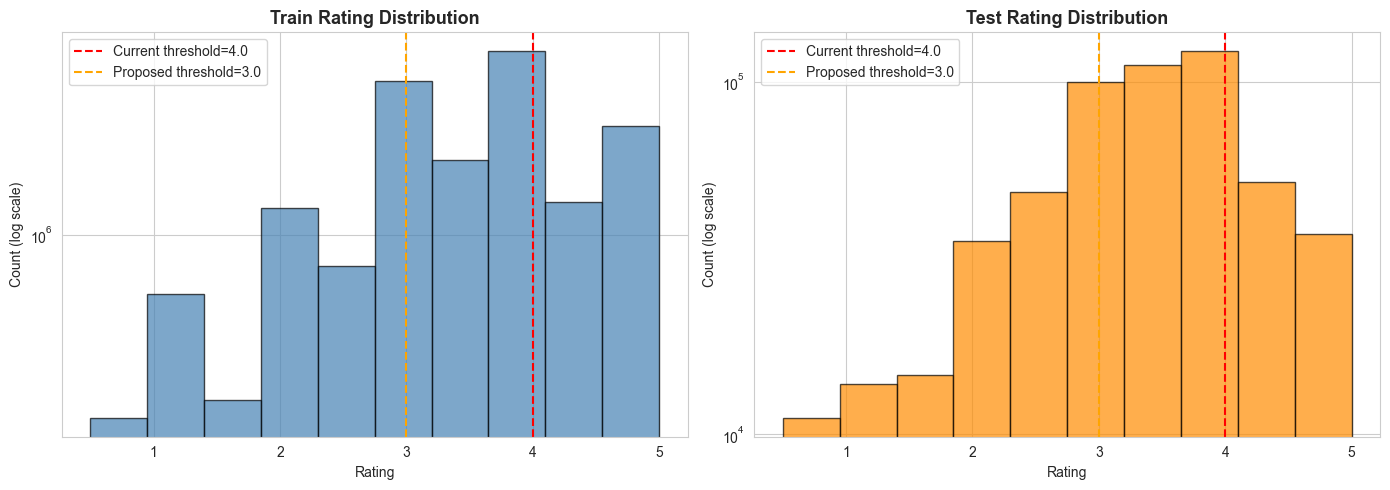

In [4]:
# Histogram: rating distribution in train vs test
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train_df['rating'], bins=10, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Train Rating Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count (log scale)')
axes[0].set_yscale('log')
axes[0].axvline(x=4.0, color='red', linestyle='--', label='Current threshold=4.0')
axes[0].axvline(x=3.0, color='orange', linestyle='--', label='Proposed threshold=3.0')
axes[0].legend()

axes[1].hist(test_df['rating'], bins=10, color='darkorange', edgecolor='black', alpha=0.7)
axes[1].set_title('Test Rating Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Count (log scale)')
axes[1].set_yscale('log')
axes[1].axvline(x=4.0, color='red', linestyle='--', label='Current threshold=4.0')
axes[1].axvline(x=3.0, color='orange', linestyle='--', label='Proposed threshold=3.0')
axes[1].legend()

plt.tight_layout()
plt.show()

In [5]:
# Cumulative ratio at each threshold
thresholds = [2.5, 3.0, 3.5, 4.0, 4.5]
print("=== Cumulative positive ratio at each threshold ===")
print(f"{'Threshold':<12}{'Train Pos':>15}{'Train %':>12}{'Test Pos':>15}{'Test %':>12}")
print("-" * 65)
for t in thresholds:
    train_pos = (train_df['rating'] >= t).sum()
    train_pct = 100.0 * train_pos / len(train_df)
    test_pos = (test_df['rating'] >= t).sum()
    test_pct = 100.0 * test_pos / len(test_df)
    print(f">= {t:<10}{train_pos:>15,}{train_pct:>11.2f}%{test_pos:>15,}{test_pct:>11.2f}%")

=== Cumulative positive ratio at each threshold ===
Threshold         Train Pos     Train %       Test Pos      Test %
-----------------------------------------------------------------
>= 2.5            15,195,160      86.83%        473,253      86.30%
>= 3.0            14,428,374      82.45%        424,527      77.42%
>= 3.5            10,659,284      60.91%        324,219      59.13%
>= 4.0             8,750,986      50.01%        212,129      38.68%
>= 4.5             3,873,166      22.13%         89,179      16.26%


## 3. Threshold Comparison Table

So sánh ảnh hưởng của mỗi threshold lên per-user statistics và stratified split feasibility.

In [7]:
# For each threshold: compute total positives, per-user positive stats, and singleton counts
thresholds = [2.5, 3.0, 3.5, 4.0, 4.5]
rows = []

for t in thresholds:
    implicit = DataPreprocessor.to_implicit(train_df, threshold=t)
    user_counts = implicit.groupby('userId').size()
    n_users_with_pos = len(user_counts)
    n_singleton = (user_counts == 1).sum()
    n_lt2 = (user_counts < 2).sum()
    n_ge2 = (user_counts >= 2).sum()
    pct_singleton = 100.0 * n_singleton / n_users_with_pos if n_users_with_pos else 0
    pct_lt2 = 100.0 * n_lt2 / n_users_with_pos if n_users_with_pos else 0
    stratified_ok = (n_lt2 == 0)
    rows.append({
        'threshold': t,
        'pos_count': len(implicit),
        'pos_pct': 100.0 * len(implicit) / len(train_df),
        'users_with_pos': n_users_with_pos,
        'users_ge2_pos': n_ge2,
        'singleton_users': n_singleton,
        'pct_singleton': pct_singleton,
        'users_lt2': n_lt2,
        'stratified_ok': 'OK' if stratified_ok else f'FAIL ({n_lt2} users <2)',
    })

comp_df = pd.DataFrame(rows)
print("=== Threshold Comparison (TRAIN set) ===")
print(comp_df.to_string(index=False, float_format=lambda x: f'{x:.2f}'))

Implicit conversion: 15,195,160 / 17,500,066 (86.8%) positive interactions
Implicit conversion: 14,428,374 / 17,500,066 (82.4%) positive interactions
Implicit conversion: 10,659,284 / 17,500,066 (60.9%) positive interactions
Implicit conversion: 8,750,986 / 17,500,066 (50.0%) positive interactions
Implicit conversion: 3,873,166 / 17,500,066 (22.1%) positive interactions
=== Threshold Comparison (TRAIN set) ===
 threshold  pos_count  pos_pct  users_with_pos  users_ge2_pos  singleton_users  pct_singleton  users_lt2        stratified_ok
      2.50   15195160    86.83          122001         121969               32           0.03         32   FAIL (32 users <2)
      3.00   14428374    82.45          121984         121944               40           0.03         40   FAIL (40 users <2)
      3.50   10659284    60.91          121905         121786              119           0.10        119  FAIL (119 users <2)
      4.00    8750986    50.01          121829         121591              238    

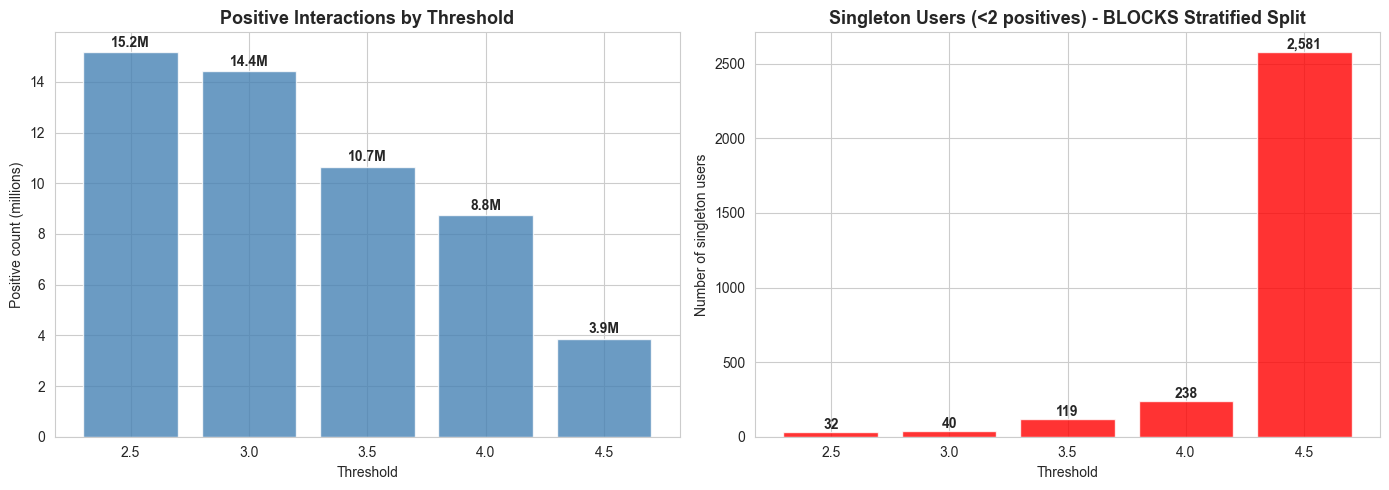

In [8]:
# Bar chart: singleton users vs total users at each threshold
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: total positive count per threshold
axes[0].bar(comp_df['threshold'].astype(str), comp_df['pos_count'] / 1e6, color='steelblue', alpha=0.8)
axes[0].set_title('Positive Interactions by Threshold', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Threshold')
axes[0].set_ylabel('Positive count (millions)')
for i, v in enumerate(comp_df['pos_count']):
    axes[0].text(i, v / 1e6 + 0.2, f'{v/1e6:.1f}M', ha='center', fontweight='bold')

# Right: singleton users count
colors = ['green' if v == 0 else 'red' for v in comp_df['singleton_users']]
axes[1].bar(comp_df['threshold'].astype(str), comp_df['singleton_users'], color=colors, alpha=0.8)
axes[1].set_title('Singleton Users (<2 positives) - BLOCKS Stratified Split', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('Number of singleton users')
for i, v in enumerate(comp_df['singleton_users']):
    axes[1].text(i, v + 20, f'{v:,}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Per-User Positive Count Distribution

Phân tích chi tiết số positive per user ở threshold=4.0 (current) và threshold=3.0 (proposed).

In [9]:
# Compare per-user positive count distribution at threshold=4.0 vs 3.0
implicit_4 = DataPreprocessor.to_implicit(train_df, threshold=4.0)
implicit_3 = DataPreprocessor.to_implicit(train_df, threshold=3.0)

counts_4 = implicit_4.groupby('userId').size()
counts_3 = implicit_3.groupby('userId').size()

for label, counts in [('threshold=4.0', counts_4), ('threshold=3.0', counts_3)]:
    print(f"=== Per-user positive count @ {label} ===")
    print(f"  Mean:    {counts.mean():.2f}")
    print(f"  Median:  {counts.median():.2f}")
    print(f"  Std:     {counts.std():.2f}")
    print(f"  Min:     {counts.min()}")
    print(f"  Max:     {counts.max()}")
    print(f"  p25:     {counts.quantile(0.25):.2f}")
    print(f"  p75:     {counts.quantile(0.75):.2f}")
    print(f"  p95:     {counts.quantile(0.95):.2f}")
    print(f"  p99:     {counts.quantile(0.99):.2f}")
    print(f"  Users w/ 1 pos:    {(counts == 1).sum():,}")
    print(f"  Users w/ <2 pos:   {(counts < 2).sum():,}")
    print(f"  Users w/ >=2 pos:  {(counts >= 2).sum():,}")
    print()

Implicit conversion: 8,750,986 / 17,500,066 (50.0%) positive interactions
Implicit conversion: 14,428,374 / 17,500,066 (82.4%) positive interactions
=== Per-user positive count @ threshold=4.0 ===
  Mean:    71.83
  Median:  37.00
  Std:     101.74
  Min:     1
  Max:     3122
  p25:     19.00
  p75:     84.00
  p95:     247.00
  p99:     491.72
  Users w/ 1 pos:    238
  Users w/ <2 pos:   238
  Users w/ >=2 pos:  121,591

=== Per-user positive count @ threshold=3.0 ===
  Mean:    118.28
  Median:  58.00
  Std:     177.53
  Min:     1
  Max:     8156
  p25:     30.00
  p75:     132.00
  p95:     417.00
  p99:     863.17
  Users w/ 1 pos:    40
  Users w/ <2 pos:   40
  Users w/ >=2 pos:  121,944



In [ ]:
# Histograms side by side: per-user positive counts
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(counts_4, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Per-User Positive Count (threshold=4.0)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Positive count per user')
axes[0].set_ylabel('Number of users')
axes[0].axvline(x=1, color='red', linestyle='--', label=f'Singleton line (1 pos) | {(counts_4 == 1).sum()} users')
axes[0].legend()

axes[1].hist(counts_3, bins=50, color='darkorange', edgecolor='black', alpha=0.7)
axes[1].set_title('Per-User Positive Count (threshold=3.0)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Positive count per user')
axes[1].set_ylabel('Number of users')
axes[1].axvline(x=1, color='red', linestyle='--', label=f'Singleton line (1 pos) | {(counts_3 == 1).sum()} users')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Zoom into the singleton zone (users with very few positives)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(counts_4[counts_4 <= 10], bins=10, color='steelblue', edgecolor='black', alpha=0.8)
axes[0].set_title('Per-User Positive Count (threshold=4.0) - ZOOM: <= 10', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Positive count per user')
axes[0].set_ylabel('Number of users')
axes[0].axvline(x=1, color='red', linestyle='--', label=f'1 pos: {(counts_4 == 1).sum():,} users')
axes[0].legend()

axes[1].hist(counts_3[counts_3 <= 10], bins=10, color='darkorange', edgecolor='black', alpha=0.8)
axes[1].set_title('Per-User Positive Count (threshold=3.0) - ZOOM: <= 10', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Positive count per user')
axes[1].set_ylabel('Number of users')
axes[1].axvline(x=1, color='red', linestyle='--', label=f'1 pos: {(counts_3 == 1).sum():,} users')
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Stratified Split Feasibility Check

Test xem `train_test_split(stratify=userId)` có chạy được không ở mỗi threshold (theo đúng cách notebook 02 đang dùng).

In [10]:
from sklearn.model_selection import train_test_split

thresholds = [2.5, 3.0, 3.5, 4.0, 4.5]
print("=== Stratified Split Feasibility ===")
print(f"{'Threshold':<12}{'Singletons':>15}{'Status':>30}")
print("-" * 60)

for t in thresholds:
    implicit = DataPreprocessor.to_implicit(train_df, threshold=t)
    user_counts = implicit.groupby('userId').size()
    n_singleton = int((user_counts == 1).sum())
    try:
        _a, _b = train_test_split(
            implicit, test_size=0.2, random_state=42, stratify=implicit['userId']
        )
        status = 'OK'
    except ValueError as e:
        first_line = str(e).split('\n')[0]
        status = f'FAIL ({n_singleton} singletons)'
    print(f">= {t:<10}{n_singleton:>15,}{status:>30}")

=== Stratified Split Feasibility ===
Threshold        Singletons                        Status
------------------------------------------------------------
Implicit conversion: 15,195,160 / 17,500,066 (86.8%) positive interactions
>= 2.5                    32          FAIL (32 singletons)
Implicit conversion: 14,428,374 / 17,500,066 (82.4%) positive interactions
>= 3.0                    40          FAIL (40 singletons)
Implicit conversion: 10,659,284 / 17,500,066 (60.9%) positive interactions
>= 3.5                   119         FAIL (119 singletons)
Implicit conversion: 8,750,986 / 17,500,066 (50.0%) positive interactions
>= 4.0                   238         FAIL (238 singletons)
Implicit conversion: 3,873,166 / 17,500,066 (22.1%) positive interactions
>= 4.5                 2,581        FAIL (2581 singletons)


## 6. Train/Val Split Simulation

So sánh 2 phương pháp chia train/val:
- **A. Stratified split**: `train_test_split(stratify=userId)` - yêu cầu mỗi user có >= 2 positives
- **B. Per-user group split**: groupby userId -> 80/20 trong từng user, singleton users -> toàn bộ vào train_sub

In [11]:
def stratified_split(df):
    """A. Standard stratified split (notebook 02's current approach)."""
    return train_test_split(df, test_size=0.2, random_state=42, stratify=df['userId'])

def peruser_split(df):
    """B. Per-user group split (handles singletons)."""
    train_parts, val_parts = [], []
    singleton_count = 0
    for _uid, _grp in df.groupby('userId', sort=False):
        if len(_grp) >= 2:
            _tr, _va = train_test_split(_grp, test_size=0.2, random_state=42, shuffle=True)
        else:
            _tr, _va = _grp, _grp.iloc[0:0]
            singleton_count += 1
        train_parts.append(_tr)
        val_parts.append(_va)
    train_sub = pd.concat(train_parts, ignore_index=True)
    val = pd.concat(val_parts, ignore_index=True)
    return train_sub, val, singleton_count

print("=== Train/Val Split Simulation ===")
print(f"{'Threshold':<12}{'Method':<20}{'Train':>15}{'Val':>15}{'Singletons':>15}{'Users in Val':>15}")
print("-" * 92)

for t in [3.0, 3.5, 4.0]:
    implicit = DataPreprocessor.to_implicit(train_df, threshold=t)
    # Method A
    try:
        a_tr, a_va = stratified_split(implicit)
        a_status = f'{len(a_tr):>15,}{len(a_va):>15,}{"-":>15}{a_va["userId"].nunique():>15,}'
    except ValueError:
        a_status = f"{'FAIL':>15}{'-':>15}{'-':>15}{'-':>15}"
    print(f">= {t:<10}{'A.Stratified':<20}{a_status}")
    # Method B
    b_tr, b_va, b_single = peruser_split(implicit)
    print(f">= {t:<10}{'B.Per-user':<20}{len(b_tr):>15,}{len(b_va):>15,}{b_single:>15,}{b_va['userId'].nunique():>15,}")
    print()

=== Train/Val Split Simulation ===
Threshold   Method                        Train            Val     Singletons   Users in Val
--------------------------------------------------------------------------------------------
Implicit conversion: 14,428,374 / 17,500,066 (82.4%) positive interactions
>= 3.0       A.Stratified                   FAIL              -              -              -
>= 3.0       B.Per-user               11,494,289      2,934,085             40        121,944

Implicit conversion: 10,659,284 / 17,500,066 (60.9%) positive interactions
>= 3.5       A.Stratified                   FAIL              -              -              -
>= 3.5       B.Per-user                8,478,729      2,180,555            119        121,786

Implicit conversion: 8,750,986 / 17,500,066 (50.0%) positive interactions
>= 4.0       A.Stratified                   FAIL              -              -              -
>= 4.0       B.Per-user                6,952,255      1,798,731            238     

In [12]:
# Detailed comparison at threshold=3.0 (proposed): how many val users have held-out items
implicit = DataPreprocessor.to_implicit(train_df, threshold=3.0)
b_tr, b_va, b_single = peruser_split(implicit)

train_users = set(b_tr['userId'].unique())
val_users = set(b_va['userId'].unique())
users_in_both = train_users & val_users

# Warm filter on val (mimic EvaluationPipeline behavior)
train_movies = set(b_tr['movieId'].unique())
val_warm = b_va[b_va['userId'].isin(train_users) & b_va['movieId'].isin(train_movies)]
val_warm_users = set(val_warm['userId'].unique())

print(f"=== Threshold=3.0 + Per-user Split details ===")
print(f"Train rows:           {len(b_tr):,}")
print(f"Val rows (raw):       {len(b_va):,}")
print(f"Val rows (warm-only): {len(val_warm):,}")
print(f"Train users:          {len(train_users):,}")
print(f"Val users (raw):      {len(val_users):,}")
print(f"Val users (warm):     {len(val_warm_users):,}")
print(f"Users in both:        {len(users_in_both):,}")
print(f"Singleton users:      {b_single:,}")
print(f"Val mean per user:    {val_warm.groupby('userId').size().mean():.2f}")
print(f"Val median per user:  {val_warm.groupby('userId').size().median():.2f}")
print(f"Val max per user:     {val_warm.groupby('userId').size().max()}")

Implicit conversion: 14,428,374 / 17,500,066 (82.4%) positive interactions
=== Threshold=3.0 + Per-user Split details ===
Train rows:           11,494,289
Val rows (raw):       2,934,085
Val rows (warm-only): 2,933,366
Train users:          121,984
Val users (raw):      121,944
Val users (warm):     121,943
Users in both:        121,944
Singleton users:      40
Val mean per user:    24.06
Val median per user:  12.00
Val max per user:     1582


## 7. Recommendation & Next Steps

### Tổng kết phân tích

Dựa trên các phân tích ở trên và Section 8 (temporal feasibility), đưa ra đề xuất cuối cùng.

### Key findings

1. **Rating distribution** trong train: mean=3.525, median=4.0 (skewed toward positive).
   Test mean=3.354 (lower because temporal split holds newer ratings).
2. **Singleton users** tồn tại ở MỌI threshold (40 user ở 3.0, 238 user ở 4.0).
   Ngay cả threshold=2.5 cũng có 32 singleton user -> stratified split KHÔNG BAO GIỜ hoạt động trên ML-25M này.
3. **Threshold càng cao** -> càng nhiều singleton users (vì user có ít rating cao).
4. **Per-user group split** robust với mọi threshold, không cần đổi threshold.
5. **62.72% user** có rating span < 1 ngày (rating tập trung trong 1 ngày), 88.12% < 365 ngày.
   Tuy nhiên median val rows per user sau temporal split = 7 (mean=14.40) -> val set vẫn đủ dày.

### Recommendation cuối cùng

**DECISION: Threshold=4.0 + temporal_user_split (val = 20% rating mới nhất của mỗi user) + test_ml25m.csv (đã có từ notebook 00)**

- **Threshold**: 4.0 (industry standard cho explicit feedback, 50% positive đủ dày)
- **Validation split**: `temporal_user_split(val_ratio=0.2)` - per-user temporal split
  - Mỗi user: sort theo `timestamp`, lấy 20% rating mới nhất làm val
  - Singleton (1 positive) -> toàn bộ vào train_sub (giống logic hiện tại)
- **Test set**: `data/processed/test_ml25m.csv` (đã là 30% tương lai + filter cold-start từ notebook 00)
  - Dùng 1 lần cuối cùng để báo cáo metric, KHÔNG dùng cho hyperparameter tuning

### Lý do temporal split thay vì random split

Per-user random split có thể tạo **temporal leakage**: val rating của user X có thể có
timestamp cũ hơn train_sub rating cùng user X, khiến metric val over-optimistic.
Temporal split đảm bảo val luôn nằm "trong tương lai" của train_sub -> metric phản ánh
đúng khả năng dự đoán tương lai của model.

### Lý do KHÔNG dùng test_ml25m.csv làm val

Nếu dùng test_ml25m.csv (đã có sẵn) để tune hyperparameter (factors, regularization, alpha):
- Sẽ **overfit test set** -> metric báo cáo cuối cùng bị inflated
- Không đại diện cho production performance
- Convention ML chuẩn: train_sub -> tune hyperparams trên val -> đánh giá cuối trên test (1 lần)

### Next steps

1. Implement `temporal_user_split` trong `src/data_loader.py`
2. Refactor notebook 02 cell In[5): thay random split bằng `temporal_user_split`
3. Thêm final evaluation cell trên `test_ml25m.csv` (sau khi chốt best params)
4. Re-run notebook 02 end-to-end để verify metrics


## 8. Temporal Split Feasibility Check

Trước khi refactor notebook 02 từ random split sang temporal split, cần verify rằng
`train_ml25m.csv` có đủ dày để hỗ trợ temporal split trong từng user. Cần trả lời:

1. Phạm vi thời gian của train (có kéo dài nhiều năm không?)
2. Rating span per user (mỗi user rating trong bao lâu?)
3. Phân bố rating theo thời gian (có đều không?)
4. Ước lượng val size sau temporal split (đủ lớn để tune hyperparams không?)

Kết quả sẽ quyết định: dùng per-user temporal split hay global temporal split.

In [ ]:
# Cell 1: Phạm vi thời gian của train_ml25m.csv
train_df['datetime'] = pd.to_datetime(train_df['timestamp'], unit='s')
dt_min = train_df['datetime'].min()
dt_max = train_df['datetime'].max()
delta = dt_max - dt_min
print(f"Train range : {dt_min} -> {dt_max}")
print(f"Duration    : {delta.days:,} days ({delta.days / 365.25:.2f} years)")


In [ ]:
# Cell 2: Rating span per user (số ngày từ rating đầu đến rating cuối)
span = train_df.groupby('userId')['datetime'].agg(
    lambda s: (s.max() - s.min()).days
)
print(f"Users total              : {len(span):,}")
print(f"\nRating span (days) per user:")
print(f"  Median  : {span.median():.0f}")
print(f"  p25/p75 : {span.quantile(0.25):.0f} / {span.quantile(0.75):.0f}")
print(f"  p10/p90 : {span.quantile(0.10):.0f} / {span.quantile(0.90):.0f}")
print(f"  Users with span < 1 day   : {(span < 1).sum():,} "
      f"({(span<1).mean()*100:.2f}%)")
print(f"  Users with span < 30 days : {(span < 30).sum():,} "
      f"({(span<30).mean()*100:.2f}%)")
print(f"  Users with span < 365 days: {(span < 365).sum():,} "
      f"({(span<365).mean()*100:.2f}%)")


In [ ]:
# Cell 3: Phân bố rating theo năm
train_df['year'] = train_df['datetime'].dt.year
yearly = train_df.groupby('year').size()
yearly.plot(kind='bar', figsize=(12, 4), title='Rating count by year')
plt.xlabel('Year')
plt.ylabel('Number of ratings')
plt.tight_layout()
plt.show()
print(f"\nTotal: {yearly.sum():,}")


In [ ]:
# Cell 4: Ước lượng val size + singleton users sau temporal split
implicit_4 = DataPreprocessor.to_implicit(train_df, threshold=4.0)
val_estimate = int(len(implicit_4) * 0.2)
print(f"Implicit (>=4.0)            : {len(implicit_4):,} rows")
print(f"Estimated val size          : {val_estimate:,} rows (20% of implicit)")
print(f"Estimated train_sub size    : {len(implicit_4) - val_estimate:,} rows")

# Singleton users sau implicit
n_per_user = implicit_4.groupby('userId').size()
singleton = int((n_per_user == 1).sum())
multi = int((n_per_user >= 2).sum())
print(f"\nSingleton users (1 positive): {singleton:,} "
      f"({singleton/len(n_per_user)*100:.2f}%)")
print(f"Multi-rating users          : {multi:,} "
      f"(candidates for temporal split)")

# Per-user val size
val_per_user = np.maximum(1, np.round(n_per_user[n_per_user >= 2] * 0.2).astype(int))
print(f"\nVal rows per user: median={int(np.median(val_per_user))}, "
      f"mean={val_per_user.mean():.2f}, "
      f"p25={int(np.quantile(val_per_user, 0.25))}, "
      f"p75={int(np.quantile(val_per_user, 0.75))}")

# Verdict
print("\n" + "=" * 60)
print("VERDICT:")
if (singleton / len(n_per_user) * 100) < 5 and val_estimate >= 500_000:
    print(f"  FEASIBLE: val_size={val_estimate:,} >= 500K, "
          f"singleton={singleton/len(n_per_user)*100:.2f}% < 5%")
    print("  -> Su dung per-user temporal split (temporal_user_split)")
else:
    print(f"  CAN NHAC: val_size={val_estimate:,}, singleton={singleton/len(n_per_user)*100:.2f}%")
    print("  -> Co the can global temporal split thay vi per-user")
